In [1]:
import sys
from pathlib import Path

print("사용 중인 파이썬:", sys.executable)
print("현재 작업 폴더:", Path.cwd())

사용 중인 파이썬: c:\Users\a__hm\anaconda3\envs\hw1\python.exe
현재 작업 폴더: c:\Users\a__hm\data\credit-card-fds\experiments


In [2]:
# 프로젝트 최상위 폴더
PROJECT_ROOT = Path.cwd().parent

# 공통 함수가 있는 src 폴더를 파이썬 검색 경로에 추가
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from utils import (
    load_and_preprocess_data,
    evaluate_fds_model,
    evaluate_thresholds,
    plot_and_save_simulation,
)

# 데이터를 불러올 위치이자 결과 CSV를 저장할 위치
DATA_DIR = PROJECT_ROOT / "data" / "processed"

X_train, y_train, X_val, y_val = load_and_preprocess_data(DATA_DIR)

print("학습 데이터:", X_train.shape)
print("검증 데이터:", X_val.shape)

[Data Loaded] Train: (198621, 30), Validation: (42562, 30)
학습 데이터: (198621, 30)
검증 데이터: (42562, 30)


In [3]:
print("프로젝트 폴더:", PROJECT_ROOT)

utils_files = list(PROJECT_ROOT.rglob("utils.py"))
print("찾은 utils.py:", utils_files)

프로젝트 폴더: c:\Users\a__hm\data\credit-card-fds
찾은 utils.py: []


In [5]:
%pip install torch koreanize-matplotlib xgboost

   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 1.0/124.1 MB 5.6 MB/s eta 0:00:23
    --------------------------------------- 2.4/124.1 MB 6.1 MB/s eta 0:00:20
    --------------------------------------- 2.9/124.1 MB 5.1 MB/s eta 0:00:24
   - -------------------------------------- 3.7/124.1 MB 4.4 MB/s eta 0:00:28
   - -------------------------------------- 4.2/124.1 MB 4.3 MB/s eta 0:00:29
   - -------------------------------------- 5.0/124.1 MB 3.8 MB/s eta 0:00:32
   - -------------------------------------- 5.2/124.1 MB 3.8 MB/s eta 0:00:32
   - -------------------------------------- 5.8/124.1 MB 3.4 MB/s eta 0:00:35
   - -------------------------------------- 6.0/124.1 MB 3.3 MB/s eta 0:00:36
   -- ------------------------------------- 6.3/124.1 MB 3.1 MB/s eta 0:00:39
   -- ------------------------------------- 6.6/124.1 MB 2.9 MB/s eta 0:00:41
   -- ------------------------------------- 6.8/124.1 MB 2.8 MB/s eta 0

In [ ]:
#랜덤 포레스트 학습시켜주기
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

print("랜덤포레스트 학습 시작")

rf_model.fit(X_train, y_train)

print("랜덤포레스트 학습 완료!")

랜덤포레스트 학습 시작
랜덤포레스트 학습 완료!


In [5]:
# ============================================================
# 랜덤포레스트 검증 성능 평가 및 결과 저장
# ============================================================
# 목적: 학습한 모델을 검증 데이터에 적용하여 사기 탐지 성능 확인
# 예측: 사기 클래스(1)의 예측 확률이 0.5 이상이면 사기로 판단
# 평가: 공통 함수 evaluate_fds_model로 AP(PR_AUC), Recall,
#       Precision, F1, Accuracy 및 혼동행렬 건수 산출
# 저장: data/processed/yemok_rf_validation_metrics.csv
# 참고: 임계값 0.5에서의 초기 평가이며, 최적 임계값은 아직 선택하지 않음
#       테스트 데이터는 사용하지 않음
# ============================================================
import pandas as pd

# 검증 거래마다 사기일 확률 계산
rf_prob = rf_model.predict_proba(X_val)[:, 1]

# 사기 확률 0.5 이상이면 사기(1), 미만이면 정상(0)
rf_pred = (rf_prob >= 0.5).astype(int)

# 동경님의 공통 함수로 성능 평가
rf_metrics = evaluate_fds_model(
    "RandomForest", y_val, rf_pred, rf_prob
)

# 평가 결과를 표로 변환
rf_metrics_df = pd.DataFrame([rf_metrics])
rf_metrics_df["Split"] = "validation"
rf_metrics_df["Threshold"] = 0.5

# data/processed에 CSV 저장
rf_metrics_df.to_csv(
    DATA_DIR / "yemok_rf_validation_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

print("랜덤포레스트 성능지표 CSV 저장 완료!")


================ [RandomForest] 평가 결과 ================
1. Accuracy  (정확도) : 0.99937
2. PR-AUC    (평균정밀도): 0.83081 ★
3. Recall    (재현율)  : 0.66216
4. Precision (정밀도)  : 0.96078
5. F1-Score  (조화평균): 0.78400
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[42486     2]
 [   25    49]]
 - TN(정상 예측 성공): 42,486건 | FP(오탐 / 오인 신고): 2건 | FN(미탐 / 놓친 사기): 25건 | TP(사기 탐지 성공): 49건

랜덤포레스트 성능지표 CSV 저장 완료!


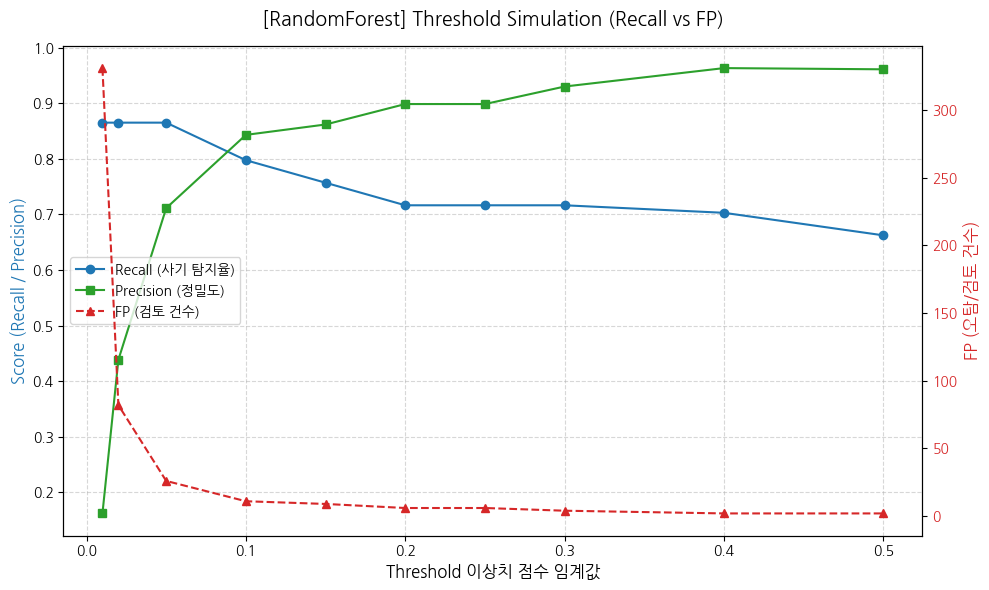

[저장 완료] 그래프 파일: c:\Users\a__hm\data\credit-card-fds\reports\figures\yemok_rf_validation_simulation.png


,Threshold,Recall,Precision,F1-Score,TP (사기 탐지),FP (오탐/검토 대상),FN (놓친 사기),Total Flagged (총 경고),Model,Split
0,0.01,0.864865,0.162025,0.272921,64,331,10,395,RandomForest,validation
1,0.02,0.864865,0.438356,0.581818,64,82,10,146,RandomForest,validation
2,0.05,0.864865,0.711111,0.780488,64,26,10,90,RandomForest,validation
3,0.10,0.797297,0.842857,0.819444,59,11,15,70,RandomForest,validation
4,0.15,0.756757,0.861538,0.805755,56,9,18,65,RandomForest,validation
5,0.20,0.716216,0.898305,0.796992,53,6,21,59,RandomForest,validation
6,0.25,0.716216,0.898305,0.796992,53,6,21,59,RandomForest,validation
7,0.30,0.716216,0.929825,0.809160,53,4,21,57,RandomForest,validation
8,0.40,0.702703,0.962963,0.812500,52,2,22,54,RandomForest,validation
9,0.50,0.662162,0.960784,0.784000,49,2,25,51,RandomForest,validation


In [6]:
# ============================================================
# 랜덤포레스트 임계값별 검토 건수 시뮬레이션
# 목적: 사기 판단 기준을 바꿨을 때 탐지율과 검토 부담 비교
# 주의: 건수는 검증 데이터 전체 기준이며, 하루 기준은 아님
# ============================================================

# 낮은 임계값부터 기존 기준인 0.5까지 비교
rf_thresholds = [
    0.01, 0.02, 0.05, 0.10, 0.15,
    0.20, 0.25, 0.30, 0.40, 0.50,
]

# 공통 함수로 임계값별 성능과 검토 건수 계산
rf_simulation = evaluate_thresholds(
    y_val,
    rf_prob,
    thresholds=rf_thresholds,
)

# 팀원이 모델과 평가 데이터 종류를 구분할 수 있도록 표시
rf_simulation["Model"] = "RandomForest"
rf_simulation["Split"] = "validation"

# 총 검토 건수는 TP + FP이며, 결과 표의 Total Flagged 열에 기록됨
rf_simulation.to_csv(
    DATA_DIR / "yemok_rf_validation_thresholds.csv",
    index=False,
    encoding="utf-8-sig",
)

# 공통 함수로 그래프 출력 및 reports/figures에 저장
# 이 그래프의 오른쪽 축은 총 검토 건수가 아닌 FP(오탐 건수)임
plot_and_save_simulation(
    rf_simulation,
    model_name="RandomForest",
    filename="yemok_rf_validation_simulation.png",
    figures_dir=PROJECT_ROOT / "reports" / "figures",
)

# 임계값별 상세 결과를 표로 표시
display(rf_simulation)

In [7]:

# ============================================================
# XGBoost 학습: scale_pos_weight로 클래스 불균형 반영
# 목적: 정상 거래에 비해 매우 적은 사기 거래에 학습 가중치 부여
# 가중치 계산: 학습 데이터의 정상 건수 / 사기 건수
# 주의: 가중치 계산과 학습에는 검증·테스트 데이터를 사용하지 않음
# ============================================================

from xgboost import XGBClassifier

# 학습 데이터에서 정상(0)과 사기(1) 거래 건수 계산
normal_count = int((y_train == 0).sum())
fraud_count = int((y_train == 1).sum())

# 사기 거래가 없으면 가중치를 계산할 수 없으므로 점검
if fraud_count == 0:
    raise ValueError("학습 데이터에 사기 거래가 없습니다.")

pos_weight = normal_count / fraud_count

print("학습 정상 거래:", normal_count)
print("학습 사기 거래:", fraud_count)
print("scale_pos_weight:", pos_weight)

# 초기 비교용 모델 설정이며, 최적화된 설정은 아님
xgb_model = XGBClassifier(
    n_estimators=300,          # 순차적으로 학습할 트리 수
    max_depth=4,               # 트리 깊이를 제한하여 복잡도 조절
    learning_rate=0.05,         # 각 트리가 예측을 수정하는 정도
    subsample=0.8,             # 각 트리 학습에 사용할 행의 비율
    colsample_bytree=0.8,      # 각 트리 학습에 사용할 특성의 비율
    scale_pos_weight=pos_weight,  # 사기 클래스에 적용할 가중치
    objective="binary:logistic",  # 정상·사기 이진 분류
    eval_metric="aucpr",       # XGBoost 내부 평가 지표 설정
    tree_method="hist",        # 히스토그램 기반 트리 학습
    random_state=42,           # 결과 재현을 위한 난수 설정
    n_jobs=-1,                 # 사용 가능한 CPU 코어 활용
)

# 학습 데이터와 정답으로 모델 학습
print("XGBoost 학습 시작")
xgb_model.fit(X_train, y_train)
print("XGBoost 학습 완료!")

학습 정상 거래: 198277
학습 사기 거래: 344
scale_pos_weight: 576.3866279069767
XGBoost 학습 시작
XGBoost 학습 완료!


In [8]:
# ============================================================
# XGBoost 검증 성능 평가 및 CSV 저장
# 목적: 랜덤포레스트와 동일한 검증 데이터·임계값으로 초기 성능 비교
# 평가: 공통 함수 evaluate_fds_model 사용
# 저장: data/processed/yemok_xgb_validation_metrics.csv
# 주의: 임계값은 0.5이며, 테스트 데이터는 사용하지 않음
# ============================================================

# 검증 거래마다 사기 클래스(1)의 예측 확률 추출
xgb_prob = xgb_model.predict_proba(X_val)[:, 1]

# 사기 예측 확률이 0.5 이상이면 사기(1), 미만이면 정상(0)
xgb_pred = (xgb_prob >= 0.5).astype(int)

# 공통 함수로 AP, Recall, Precision, F1 및 혼동행렬 등 산출
xgb_metrics = evaluate_fds_model(
    "XGBoost", y_val, xgb_pred, xgb_prob
)

# 반환된 딕셔너리를 한 행짜리 표로 변환하고 평가 조건 기록
xgb_metrics_df = pd.DataFrame([xgb_metrics])
xgb_metrics_df["Split"] = "validation"
xgb_metrics_df["Threshold"] = 0.5

# 행 번호는 제외하고, 엑셀에서 한글이 깨지지 않도록 저장
xgb_metrics_df.to_csv(
    DATA_DIR / "yemok_xgb_validation_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

print("XGBoost 성능지표 CSV 저장 완료!")


================ [XGBoost] 평가 결과 ================
1. Accuracy  (정확도) : 0.99908
2. PR-AUC    (평균정밀도): 0.81183 ★
3. Recall    (재현율)  : 0.79730
4. Precision (정밀도)  : 0.71084
5. F1-Score  (조화평균): 0.75159
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[42464    24]
 [   15    59]]
 - TN(정상 예측 성공): 42,464건 | FP(오탐 / 오인 신고): 24건 | FN(미탐 / 놓친 사기): 15건 | TP(사기 탐지 성공): 59건

XGBoost 성능지표 CSV 저장 완료!


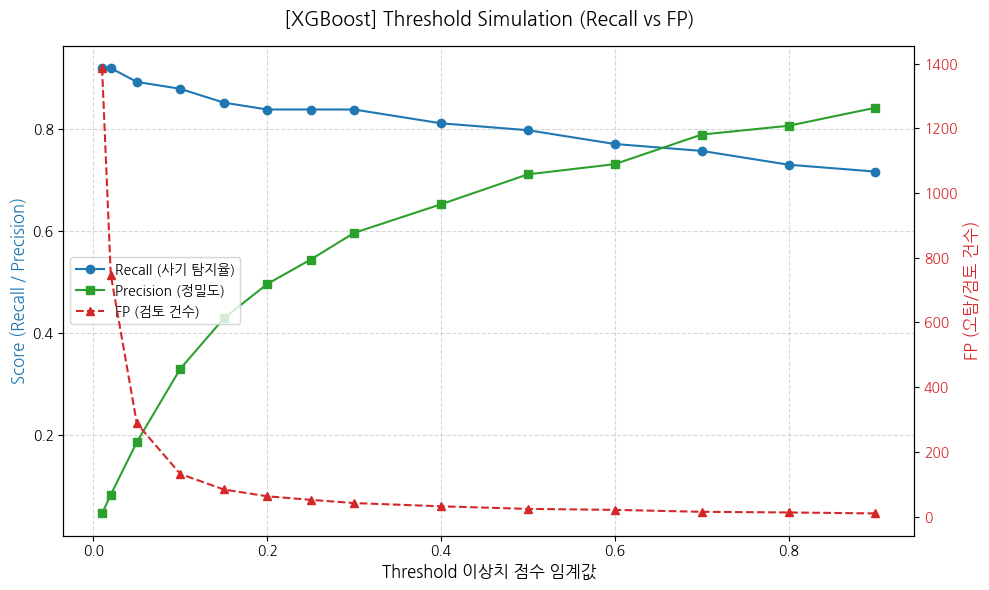

[저장 완료] 그래프 파일: c:\Users\a__hm\data\credit-card-fds\reports\figures\yemok_xgb_validation_simulation.png


,Threshold,Recall,Precision,F1-Score,TP (사기 탐지),FP (오탐/검토 대상),FN (놓친 사기),Total Flagged (총 경고),Model,Split
0,0.01,0.918919,0.046768,0.089005,68,1386,6,1454,XGBoost,validation
1,0.02,0.918919,0.083333,0.152809,68,748,6,816,XGBoost,validation
2,0.05,0.891892,0.186441,0.308411,66,288,8,354,XGBoost,validation
3,0.10,0.878378,0.329949,0.479705,65,132,9,197,XGBoost,validation
4,0.15,0.851351,0.428571,0.570136,63,84,11,147,XGBoost,validation
5,0.20,0.837838,0.496000,0.623116,62,63,12,125,XGBoost,validation
6,0.25,0.837838,0.543860,0.659574,62,52,12,114,XGBoost,validation
7,0.30,0.837838,0.596154,0.696629,62,42,12,104,XGBoost,validation
8,0.40,0.810811,0.652174,0.722892,60,32,14,92,XGBoost,validation
9,0.50,0.797297,0.710843,0.751592,59,24,15,83,XGBoost,validation


In [9]:
# ============================================================
# XGBoost 임계값별 검토 건수 시뮬레이션 및 결과 저장
# 목적: 임계값에 따른 사기 탐지율과 검토 부담 비교
# 범위: 0.01~0.90의 후보를 검증 데이터에서 평가
# 주의: 총 검토 건수는 TP + FP이며, 하루 기준 건수가 아님
# ============================================================

# 0.5보다 낮은 기준과 높은 기준을 함께 검토
xgb_thresholds = [
    0.01, 0.02, 0.05, 0.10, 0.15, 0.20,
    0.25, 0.30, 0.40, 0.50, 0.60, 0.70,
    0.80, 0.90,
]

# 공통 함수로 임계값별 Recall, Precision, 검토 건수 등 산출
xgb_simulation = evaluate_thresholds(
    y_val,
    xgb_prob,
    thresholds=xgb_thresholds,
)

# 결과를 합칠 때 모델과 평가 데이터 종류를 구분하기 위한 열
xgb_simulation["Model"] = "XGBoost"
xgb_simulation["Split"] = "validation"

# 시뮬레이션 결과를 data/processed에 CSV로 저장
xgb_simulation.to_csv(
    DATA_DIR / "yemok_xgb_validation_thresholds.csv",
    index=False,
    encoding="utf-8-sig",
)

# 공통 함수로 그래프를 출력하고 reports/figures에 저장
# 오른쪽 축은 총 검토 건수가 아닌 FP(정상 거래 오탐 건수)
plot_and_save_simulation(
    xgb_simulation,
    model_name="XGBoost",
    filename="yemok_xgb_validation_simulation.png",
    figures_dir=PROJECT_ROOT / "reports" / "figures",
)

# 임계값별 상세 결과 표시
display(xgb_simulation)

In [10]:
# ============================================================
# 랜덤포레스트·XGBoost 검증 결과 통합 및 운영 후보 비교
# 선택 기준: Recall >= 0.80인 후보 중 총 검토 건수 최소
# 동률 처리: Recall이 높은 순, 그다음 임계값이 높은 순
# 주의: 지금까지 평가한 임계값 후보 안에서만 선택
#       모든 건수는 검증 데이터 전체 기준이며 하루 기준이 아님
#       테스트 데이터는 사용하지 않음
# ============================================================

# 1. 임계값 0.5에서 계산한 두 모델의 핵심 성능지표 통합
comparison_metrics = pd.concat(
    [rf_metrics_df, xgb_metrics_df],
    ignore_index=True,
)

# 통합 성능지표를 data/processed에 저장
comparison_metrics.to_csv(
    DATA_DIR / "yemok_rf_xgb_validation_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

# 2. 두 모델의 임계값별 시뮬레이션 결과 통합
all_simulations = pd.concat(
    [rf_simulation, xgb_simulation],
    ignore_index=True,
)

# 모든 임계값 후보의 결과를 CSV로 저장
all_simulations.to_csv(
    DATA_DIR / "yemok_rf_xgb_validation_thresholds.csv",
    index=False,
    encoding="utf-8-sig",
)

# 3. 목표 Recall 80% 이상을 만족하는 후보만 추출
target_recall = 0.80

eligible = all_simulations[
    all_simulations["Recall"] >= target_recall
].copy()

# 총 검토 건수가 적은 순서로 정렬한 뒤 모델별 첫 행 선택
selected_candidates = (
    eligible.sort_values(
        ["Total Flagged (총 경고)", "Recall", "Threshold"],
        ascending=[True, False, False],
    )
    .drop_duplicates(subset="Model")
    .reset_index(drop=True)
)

# 목표를 만족하는 후보가 없는 모델도 확인
for model_name in ["RandomForest", "XGBoost"]:
    if model_name not in selected_candidates["Model"].values:
        print(f"{model_name}: Recall 80% 이상인 후보가 없습니다.")

# 4. 후보 선택 조건을 기록하고 비교 결과 저장
selected_candidates["Target_Recall"] = target_recall

selected_candidates.to_csv(
    DATA_DIR / "yemok_rf_xgb_validation_candidates.csv",
    index=False,
    encoding="utf-8-sig",
)

# 5. 팀원이 비교하기 쉽도록 주요 열만 화면에 표시
print("임계값 후보 중 Recall 80% 이상 · 최소 검토 건수 비교")

display(selected_candidates[[
    "Model",
    "Threshold",
    "Recall",
    "Precision",
    "TP (사기 탐지)",
    "FP (오탐/검토 대상)",
    "FN (놓친 사기)",
    "Total Flagged (총 경고)",
]])

print("통합 CSV 3개 저장 완료!")

임계값 후보 중 Recall 80% 이상 · 최소 검토 건수 비교


,Model,Threshold,Recall,Precision,TP (사기 탐지),FP (오탐/검토 대상),FN (놓친 사기),Total Flagged (총 경고)
0,RandomForest,0.05,0.864865,0.711111,64,26,10,90
1,XGBoost,0.40,0.810811,0.652174,60,32,14,92


통합 CSV 3개 저장 완료!


In [11]:
# ============================================================
# 산출물 저장 확인
# 목적: 팀원에게 전달할 CSV 7개와 그래프 2개의 존재·크기 점검
# CSV는 다시 읽어 행 개수도 확인
# ============================================================

# 모델별 결과 4개 + 통합 결과 3개
csv_names = [
    "yemok_rf_validation_metrics.csv",
    "yemok_rf_validation_thresholds.csv",
    "yemok_xgb_validation_metrics.csv",
    "yemok_xgb_validation_thresholds.csv",
    "yemok_rf_xgb_validation_metrics.csv",
    "yemok_rf_xgb_validation_thresholds.csv",
    "yemok_rf_xgb_validation_candidates.csv",
]

# CSV 파일을 다시 읽어 정상적으로 저장됐는지 확인
for name in csv_names:
    path = DATA_DIR / name
    if path.is_file():
        saved_df = pd.read_csv(path, encoding="utf-8-sig")
        print(f"[확인] {name}: {len(saved_df)}행")
    else:
        print(f"[누락] {name}")

# 모델별 시뮬레이션 그래프 파일 확인
figures_dir = PROJECT_ROOT / "reports" / "figures"

for name in [
    "yemok_rf_validation_simulation.png",
    "yemok_xgb_validation_simulation.png",
]:
    path = figures_dir / name
    if path.is_file() and path.stat().st_size > 0:
        print(f"[확인] {name}")
    else:
        print(f"[누락 또는 빈 파일] {name}")

[확인] yemok_rf_validation_metrics.csv: 1행
[확인] yemok_rf_validation_thresholds.csv: 10행
[확인] yemok_xgb_validation_metrics.csv: 1행
[확인] yemok_xgb_validation_thresholds.csv: 14행
[확인] yemok_rf_xgb_validation_metrics.csv: 2행
[확인] yemok_rf_xgb_validation_thresholds.csv: 24행
[확인] yemok_rf_xgb_validation_candidates.csv: 2행
[확인] yemok_rf_validation_simulation.png
[확인] yemok_xgb_validation_simulation.png
